<a href="https://colab.research.google.com/github/Riju0045/Face-Emotion-Recognition/blob/main/Face_Emotion_Recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
!unzip "/content/drive/MyDrive/archive (9).zip" -d "/content/"

Archive:  /content/drive/MyDrive/archive (9).zip
replace /content/archive (3)/Test/Anger/image0000006.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [3]:
tren = "/content/archive (3)/Train"
tst = "/content/archive (3)/Test"

In [6]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout, Dense, GlobalAveragePooling2D, Input, Lambda
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

# ============================================================
# DATA LOADING
# ============================================================
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    tren,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
     # Changed from default 'categorical' to 'int'
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    tst,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
     # Changed from default 'categorical' to 'int'
)

# NOTE: no /255 mapping here — ResNet50's preprocess_input
# (inside the model as a Lambda layer) handles normalization

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

# ============================================================
# DATA AUGMENTATION
# ============================================================
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

# ============================================================
# MODEL DEFINITION
# ============================================================
base_model = ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
base_model.trainable = False  # frozen for stage 1

model2 = Sequential([
    Input(shape=(224, 224, 3)),
    data_augmentation,
    Lambda(preprocess_input),   # ResNet50-specific preprocessing
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.3),
    Dense(128, activation="relu"),
    Dropout(0.2),
    Dense(8, activation="softmax")
])

model2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ============================================================
# STAGE 1: Train the head only (base_model frozen)
# ============================================================
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=3,
    restore_best_weights=True
)

history1 = model2.fit(
    train_ds,
    validation_data=test_ds,
    epochs=20,
    callbacks=[early_stop]
)
'''
# ============================================================
# STAGE 2: Fine-tune the base model
# ============================================================
base_model.trainable = True

# Only fine-tune the top N layers, freeze the rest
# ResNet50 has ~175 layers total — adjust based on your dataset size
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Keep BatchNorm layers frozen regardless — prevents accuracy drops during fine-tuning
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a much lower learning rate — required after changing trainable status
model2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2
)

history2 = model2.fit(
    train_ds,
    validation_data=test_ds,
    epochs=15,
    callbacks=[early_stop, reduce_lr]
)
'''

Found 16108 files belonging to 8 classes.
Found 14518 files belonging to 8 classes.
Epoch 1/20
504/504 ━━━━━━━━━━━━━━━━━━━━ 154s 283ms/step - accuracy: 0.3673 - loss: 1.6166 - val_accuracy: 0.4256 - val_loss: 1.5219
Epoch 2/20
504/504 ━━━━━━━━━━━━━━━━━━━━ 157s 312ms/step - accuracy: 0.4231 - loss: 1.4499 - val_accuracy: 0.4485 - val_loss: 1.4693
Epoch 3/20
504/504 ━━━━━━━━━━━━━━━━━━━━ 161s 319ms/step - accuracy: 0.4439 - loss: 1.4091 - val_accuracy: 0.4587 - val_loss: 1.4678
Epoch 4/20
504/504 ━━━━━━━━━━━━━━━━━━━━ 158s 313ms/step - accuracy: 0.4555 - loss: 1.3870 - val_accuracy: 0.4753 - val_loss: 1.4325
Epoch 5/20
504/504 ━━━━━━━━━━━━━━━━━━━━ 140s 277ms/step - accuracy: 0.4636 - loss: 1.3692 - val_accuracy: 0.4645 - val_loss: 1.4909
Epoch 6/20
504/504 ━━━━━━━━━━━━━━━━━━━━ 139s 276ms/step - accuracy: 0.4686 - loss: 1.3554 - val_accuracy: 0.4720 - val_loss: 1.5286
Epoch 7/20
504/504 ━━━━━━━━━━━━━━━━━━━━ 139s 276ms/step - accuracy: 0.4672 - loss: 1.3467 - val_accuracy: 0.4666 - val_loss:

'\n# ============================================================\n# STAGE 2: Fine-tune the base model\n# ============================================================\nbase_model.trainable = True\n\n# Only fine-tune the top N layers, freeze the rest\n# ResNet50 has ~175 layers total — adjust based on your dataset size\nfor layer in base_model.layers[:-20]:\n    layer.trainable = False\n\n# Keep BatchNorm layers frozen regardless — prevents accuracy drops during fine-tuning\nfor layer in base_model.layers:\n    if isinstance(layer, tf.keras.layers.BatchNormalization):\n        layer.trainable = False\n\n# Recompile with a much lower learning rate — required after changing trainable status\nmodel2.compile(\n    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),\n    loss="sparse_categorical_crossentropy",\n    metrics=["accuracy"]\n)\n\nreduce_lr = tf.keras.callbacks.ReduceLROnPlateau(\n    monitor="val_loss",\n    factor=0.5,\n    patience=2\n)\n\nhistory2 = model2.fit(\n    train_

In [7]:
base_model.trainable = True

# Only fine-tune the top N layers, freeze the rest
# ResNet50 has ~175 layers total — adjust based on your dataset size
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Keep BatchNorm layers frozen regardless — prevents accuracy drops during fine-tuning
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a much lower learning rate — required after changing trainable status
model2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2
)

history2 = model2.fit(
    train_ds,
    validation_data=test_ds,
    epochs=45,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/45
306/504 ━━━━━━━━━━━━━━━━━━━━ 34s 176ms/step - accuracy: 0.4804 - loss: 1.3366

KeyboardInterrupt: 

In [6]:
import numpy as np
from sklearn.metrics import classification_report
yt= np.concatenate([y for x, y in test_ds], axis=0)
yp= np.argmax(model2.predict(test_ds),axis=1)

454/454 ━━━━━━━━━━━━━━━━━━━━ 69s 147ms/step


In [7]:
print(classification_report(yt,yp))


              precision    recall  f1-score   support

           0       0.56      0.27      0.36      1718
           1       0.52      0.53      0.53      1312
           2       0.47      0.11      0.17      1248
           3       0.59      0.24      0.34      1664
           4       0.85      0.83      0.84      2704
           5       0.67      0.88      0.76      2368
           6       0.33      0.70      0.45      1584
           7       0.38      0.45      0.42      1920

    accuracy                           0.55     14518
   macro avg       0.55      0.50      0.48     14518
weighted avg       0.58      0.55      0.53     14518



In [8]:
import os
cn = sorted(os.listdir(tst))
print(cn)
print(len(cn))   # should print 8
print(cn)

['Anger', 'Contempt', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
8
['Anger', 'Contempt', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


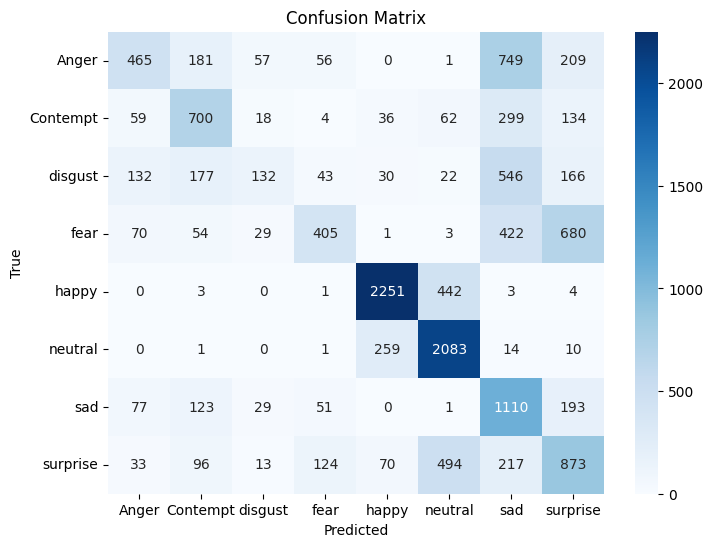

In [9]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(yt, yp)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=cn, yticklabels=cn, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

In [9]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

y_train = np.concatenate([
    labels.numpy() for _, labels in train_ds
])
classes = np.unique(y_train)
weights = compute_class_weight("balanced", classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, weights))

model2.fit(train_ds, validation_data=test_ds, epochs=35,
           callbacks=[early_stop, reduce_lr],
           class_weight=class_weight_dict)

Epoch 1/35
504/504 ━━━━━━━━━━━━━━━━━━━━ 178s 342ms/step - accuracy: 0.4870 - loss: 1.3817 - val_accuracy: 0.5155 - val_loss: 1.3642 - learning_rate: 1.0000e-05
Epoch 2/35
504/504 ━━━━━━━━━━━━━━━━━━━━ 152s 302ms/step - accuracy: 0.5016 - loss: 1.3322 - val_accuracy: 0.5342 - val_loss: 1.3944 - learning_rate: 1.0000e-05
Epoch 3/35
504/504 ━━━━━━━━━━━━━━━━━━━━ 152s 301ms/step - accuracy: 0.5107 - loss: 1.2988 - val_accuracy: 0.5406 - val_loss: 1.3304 - learning_rate: 1.0000e-05
Epoch 4/35
504/504 ━━━━━━━━━━━━━━━━━━━━ 169s 336ms/step - accuracy: 0.5269 - loss: 1.2577 - val_accuracy: 0.5514 - val_loss: 1.4368 - learning_rate: 1.0000e-05
Epoch 5/35
504/504 ━━━━━━━━━━━━━━━━━━━━ 152s 302ms/step - accuracy: 0.5373 - loss: 1.2296 - val_accuracy: 0.5587 - val_loss: 1.4341 - learning_rate: 1.0000e-05
Epoch 6/35
504/504 ━━━━━━━━━━━━━━━━━━━━ 151s 301ms/step - accuracy: 0.5525 - loss: 1.2015 - val_accuracy: 0.5692 - val_loss: 1.3780 - learning_rate: 5.0000e-06
Epoch 7/35
504/504 ━━━━━━━━━━━━━━━━━━━━ 

In [10]:
yt1= np.concatenate([y for x, y in test_ds], axis=0)
yp1= np.argmax(model2.predict(test_ds),axis=1)

454/454 ━━━━━━━━━━━━━━━━━━━━ 70s 150ms/step


In [11]:
print(classification_report(yt1,yp1))

NameError: name 'classification_report' is not defined

In [1]:
cm = confusion_matrix(yt1, yp1)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=cn, yticklabels=cn, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

NameError: name 'confusion_matrix' is not defined